# Exercises XP: Guided Student Notebook

This guided notebook follows the **exact exercise on the platform**. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear only for key concepts to support intuition and transfer to other AI topics.

## Reference from the exercise

**What you will learn**  
- The differences between traditional machine learning and deep learning.
- The structure and working of artificial neural networks. How to generate, visualize, and analyze datasets with noise.
- Techniques for fitting polynomial regression models and understanding overfitting.
- The importance of cross-validation in model selection.

**What you will create**  
- A comparative table of traditional machine learning vs deep learning.
- A simple ANN diagram with labeled components.
- A noisy dataset visualized with a scatter plot.
- Polynomial regression models of varying degrees.
- A cross-validation analysis to select an optimal polynomial degree.

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. Everything uses NumPy, Matplotlib and scikit-learn, so there is no dataset to upload. The noise uses a fixed seed (`np.random.seed(0)`), so my numbers can be repeated.

**How to read this notebook:** before every code cell there is a short **"What this cell does"** note, the code itself has a comment on each important line, and after the key outputs there is a **"What this shows"** note that explains the result.

## 🌟 Exercise 1: Deep Learning vs Traditional Machine Learning

**As stated in the exercise**  
Objective. Understand the differences between traditional machine learning and deep learning.  
Instructions. Create a table comparing Feature Engineering, Data Processing, Scalability, Pattern Discovery, and Computational Requirements. Identify one real world problem where traditional ML is better, and one where deep learning is better. Write a short paragraph explaining why deep learning has an advantage in unstructured data processing.

**Guidance**  
Use a markdown table for the comparison, keep wording concise and concrete, then write two short examples and one paragraph in full sentences.

**To-Do:** Complete the comparison table below by filling in each cell with your own wording.

| Aspect | Traditional ML | Deep Learning |
|:--|:--|:--|
| Feature Engineering | Done by hand: I choose and build the input features (ratios, counts, encodings) using domain knowledge. | Mostly automatic: the network learns its own features from raw inputs such as pixels, audio or text tokens. |
| Data Processing | Works best on structured, tabular data with clean columns. Needs scaling, encoding and feature selection. | Handles unstructured data (images, audio, text) directly. Needs less manual cleanup but much more data. |
| Scalability | Performance usually levels off as the dataset grows. Training stays fast on a CPU. | Performance keeps improving with more data and bigger models. Training scales across GPUs/TPUs. |
| Pattern Discovery | Finds the patterns the chosen features allow. Simple, often interpretable relationships (trees, linear weights). | Finds complex, non-linear, hierarchical patterns (edges → shapes → objects) that are hard to describe by hand. Less interpretable. |
| Computational Requirements | Low: a laptop CPU, seconds to minutes of training, small memory. | High: GPUs/TPUs, hours or days of training, large memory and energy cost. |

**To-Do:** Give one real world problem better suited to traditional ML and one better suited to deep learning. Explain your choices in 2–3 sentences.

**My answer:**
- **Traditional ML is better for: predicting customer churn from a bank's table of customers** (age, balance, number of products, tenure). The data is small and tabular, a gradient-boosted tree or logistic regression trains in seconds, and the bank can explain which features drive each decision.
- **Deep learning is better for: detecting tumors in medical scans (X-ray or MRI images).** The input is raw pixels with no ready-made columns, and a convolutional neural network can learn the visual features (edges, textures, shapes) by itself from many labeled images, which hand-crafted features cannot match.

**To-Do:** Write a paragraph of 3–5 sentences explaining why deep learning has an advantage in unstructured data processing, using precise terms such as representation learning and hierarchical features.

**My answer:** Unstructured data such as images, audio and text has no ready-made columns, so for traditional ML a person has to design the features by hand, which is slow and loses information. Deep learning uses **representation learning**: the network learns useful features directly from the raw input while it trains. Its stacked layers build **hierarchical features**, for example pixels → edges → textures → object parts → whole objects in an image, or characters → words → phrases → meaning in text. Because these features are optimized for the task itself and improve with more data, deep learning reaches much higher accuracy on unstructured data than models that rely on hand-made features.

## 🌟 Exercise 2: Artificial Neural Networks (ANNs)

**As stated in the exercise**  
Objective. Identify and understand the key components of an ANN.  
Instructions. Draw or use a diagram tool to create an ANN with an input layer of 3 neurons, one hidden layer of 4 neurons, and an output layer of 2 neurons. Label neurons, weights, biases, activation function, and layers. Write a short description of how information flows through the network.

**Guidance**  
A clear schematic is preferred. Ensure every requested label appears exactly once and is readable.

**What this cell does:** it draws the 3 → 4 → 2 network with Matplotlib (no extra tool needed).
- Each **neuron** is a circle. I place the circles of each layer in one column (x = 0, 1, 2).
- Each **weight** is a line from a neuron in one layer to a neuron in the next layer. Every input neuron connects to every hidden neuron (3 × 4 = 12 weights) and every hidden neuron connects to every output neuron (4 × 2 = 8 weights). This is called a *fully connected* (dense) layer.
- **Biases** are drawn as small "+1" boxes, one feeding each layer after the input. A bias is an extra number added to the weighted sum of each neuron.
- The **activation function** (σ, e.g. ReLU) is written inside the hidden and output neurons, because it is applied inside them.

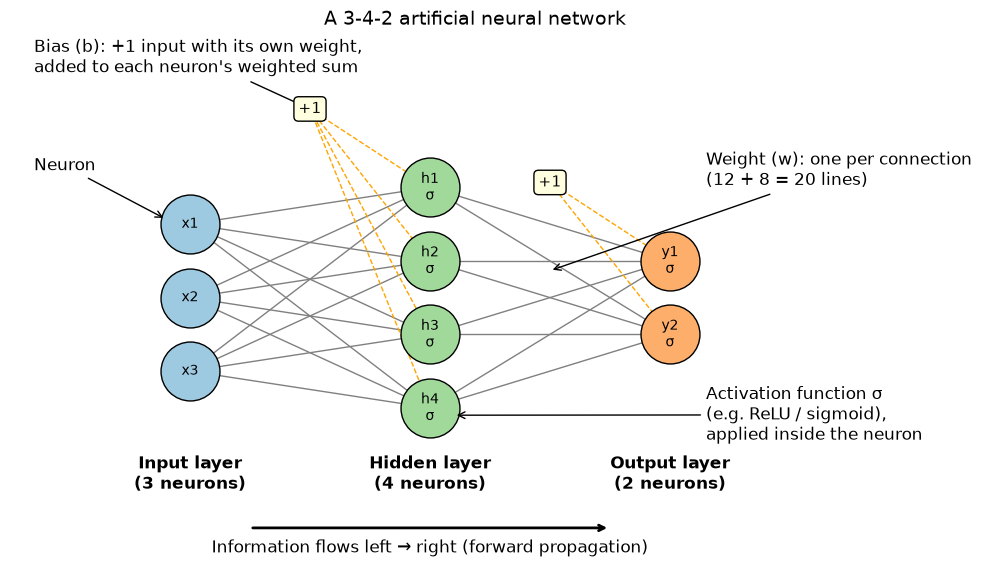

weights: 20 | biases: 6 | total parameters: 26


In [1]:
import matplotlib.pyplot as plt

layer_sizes = [3, 4, 2]                     # neurons per layer: input, hidden, output
layer_names = ["Input layer\n(3 neurons)", "Hidden layer\n(4 neurons)", "Output layer\n(2 neurons)"]
x_pos = [0, 4, 8]                           # horizontal position of each layer
colors = ["#9ecae1", "#a1d99b", "#fdae6b"]  # blue = input, green = hidden, orange = output

def y_positions(n):
    # spread n neurons evenly (1.5 units apart) around y = 0 so every layer is centred
    return [1.5 * ((n - 1) / 2 - i) for i in range(n)]

fig, ax = plt.subplots(figsize=(12, 7))

# 1) weights = lines between every neuron of layer L and every neuron of layer L+1
for L in range(len(layer_sizes) - 1):
    for y1 in y_positions(layer_sizes[L]):
        for y2 in y_positions(layer_sizes[L + 1]):
            ax.plot([x_pos[L], x_pos[L + 1]], [y1, y2], color="gray", lw=1, zorder=1)

# 2) neurons = big round markers (hidden/output neurons show the activation σ inside)
for L, n in enumerate(layer_sizes):
    ys = y_positions(n)
    ax.scatter([x_pos[L]] * n, ys, s=1800, color=colors[L], edgecolors="black", zorder=3)
    for i, y in enumerate(ys):
        label = f"x{i+1}" if L == 0 else (f"h{i+1}\nσ" if L == 1 else f"y{i+1}\nσ")
        ax.text(x_pos[L], y, label, ha="center", va="center", fontsize=10, zorder=4)
    ax.text(x_pos[L], -3.9, layer_names[L], ha="center", fontsize=12, weight="bold")   # layer labels

# 3) biases = "+1" boxes that feed the hidden and output layers (dashed orange lines)
for L in [1, 2]:
    bx, by = x_pos[L] - 2, max(y_positions(layer_sizes[L])) + 1.6
    ax.text(bx, by, "+1", ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round", fc="lightyellow", ec="black"), zorder=4)
    for y in y_positions(layer_sizes[L]):
        ax.plot([bx, x_pos[L]], [by, y], color="orange", lw=1, ls="--", zorder=1)

# 4) arrows with the component names (each label appears once)
ax.annotate("Neuron", xy=(-0.4, 1.6), xytext=(-2.6, 2.6), arrowprops=dict(arrowstyle="->"), fontsize=12)
ax.annotate("Weight (w): one per connection\n(12 + 8 = 20 lines)", xy=(6, 0.55), xytext=(8.6, 2.3),
            arrowprops=dict(arrowstyle="->"), fontsize=12)
ax.annotate("Bias (b): +1 input with its own weight,\nadded to each neuron's weighted sum", xy=(2, 3.85),
            xytext=(-2.6, 4.6), arrowprops=dict(arrowstyle="->"), fontsize=12)
ax.annotate("Activation function σ\n(e.g. ReLU / sigmoid),\napplied inside the neuron", xy=(4.4, -2.4),
            xytext=(8.6, -2.9), arrowprops=dict(arrowstyle="->"), fontsize=12)
ax.annotate("", xy=(7, -4.7), xytext=(1, -4.7), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(4, -5.2, "Information flows left → right (forward propagation)", ha="center", fontsize=12)

ax.set_xlim(-3, 12.5); ax.set_ylim(-5.6, 5.4)
ax.axis("off")
plt.title("A 3-4-2 artificial neural network", fontsize=14)
plt.show()

# number of trainable parameters = weights + biases
n_weights = 3 * 4 + 4 * 2
n_biases = 4 + 2
print("weights:", n_weights, "| biases:", n_biases, "| total parameters:", n_weights + n_biases)

**What this shows:** the network has 3 inputs, 4 hidden neurons and 2 outputs. Counting the lines gives 12 + 8 = 20 **weights**, plus one **bias** for each hidden and output neuron (4 + 2 = 6), so it has 26 numbers that training would adjust. In Keras this same network would be `Sequential([Input(shape=(3,)), Dense(4, activation="relu"), Dense(2, activation="softmax")])`, and `model.summary()` would also report 26 parameters.

**To-Do:** Provide a 3–5 sentence description of forward propagation in your diagram. Refer explicitly to inputs, weighted sums, biases, activation, and outputs.

**My answer:** The three **inputs** x1, x2, x3 enter the input layer, which only passes them on. Each of the 4 hidden neurons multiplies every input by its own **weight**, adds the products together and adds its **bias**, giving the weighted sum z = w1·x1 + w2·x2 + w3·x3 + b. The neuron then applies its **activation function** (for example ReLU, a = max(0, z)), which adds non-linearity so the network can learn curved patterns. The output layer repeats the same steps with the 4 hidden activations as its inputs, and its activation (for example softmax for two classes) turns the result into the 2 **outputs** y1 and y2, which are the network's prediction.

**Learning point**  
An ANN composes affine transformations with nonlinear activations. The affine part mixes features through weights and biases. The nonlinearity enables modeling of complex decision boundaries.

## 🌟 Exercise 3: Creating the Dataset and Visualizing the Data

**As stated in the exercise**  
Objective. Generate a dataset with noise and visualize it.  
Instructions. Import numpy, matplotlib.pyplot, and mean_squared_error from sklearn.metrics. Create 20 points using \(y = -x^2\) with Gaussian noise \(\mathcal{N}(0, 0.05)\). Plot the points with a scatter plot. Split into a training set with the first 12 points and a test set with the last 8 points.

**What this cell does (PREFILLED):** imports the three tools and creates the x values.
- `np.random.seed(0)` fixes the random generator, so the "random" noise is the same every time I run the notebook.
- `np.arange(-1, 1, 0.1)` makes numbers from -1 up to (but not including) 1 in steps of 0.1, which gives exactly 20 points: -1.0, -0.9, …, 0.9.

In [2]:
# PREFILLED: just execute
import numpy as np                                  # arrays and math
import matplotlib.pyplot as plt                     # plotting
from sklearn.metrics import mean_squared_error      # MSE = average of squared errors

np.random.seed(0)                                   # same noise every run
x = np.arange(-1, 1, 0.1)  # 20 points from -1 to <1 step 0.1
print("x shape:", x.shape)                          # (20,) = a 1-D array with 20 numbers

x shape: (20,)


**What this cell does:** creates the y values. The true rule is y = -x², a downward parabola. `np.random.normal(0, 0.05, len(x))` draws 20 random numbers from a normal (bell-shaped) distribution with mean 0 and standard deviation 0.05, and I add them to y. This noise imitates measurement error, so the points are close to the parabola but not exactly on it.

In [3]:
# To-Do: generate y with noise using np.random.normal()
noise = np.random.normal(0, 0.05, len(x))   # mean 0, std 0.05, one noise value per point
y = -x**2 + noise                            # true signal  +  noise
print("y shape:", y.shape)
print("first 3 points (x, y):", [(round(float(a), 1), round(float(b), 3)) for a, b in zip(x[:3], y[:3])])

y shape: (20,)
first 3 points (x, y): [(-1.0, -0.912), (-0.9, -0.79), (-0.8, -0.591)]


**What this cell does (PREFILLED):** draws each (x, y) pair as a dot so I can see the shape of the data.

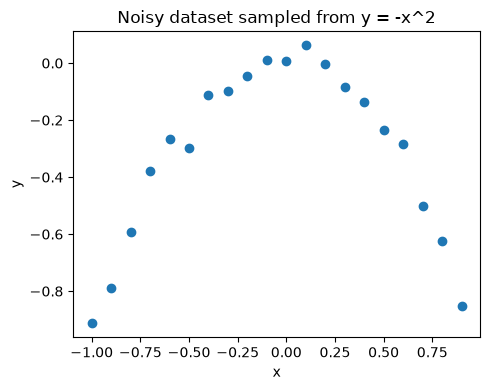

In [4]:
# PREFILLED: just execute (scatter plot of the dataset)
plt.figure(figsize=(5,4))
plt.scatter(x, y)                                  # one dot per (x, y) point
plt.title("Noisy dataset sampled from y = -x^2")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.show()

**What this shows:** the dots form a clear upside-down parabola with its top near (0, 0). The noise (std 0.05) is small compared with the range of y (from about -1 to 0), so the true shape is easy to see.

**What this cell does:** splits the data exactly as the exercise asks. Slicing `[:12]` keeps the first 12 points (x from -1.0 to 0.1) for training, and `[12:]` keeps the last 8 points (x from 0.2 to 0.9) for testing.

⚠️ **Important detail:** because x is sorted, this is *not* a random split. The test points lie entirely to the right of all the training points, so the test set checks whether a model can **extrapolate** (predict outside the range it saw), not just interpolate between training points.

train sizes: (12,) (12,) test sizes: (8,) (8,)
train x range: -1.0 to 0.1 | test x range: 0.2 to 0.9


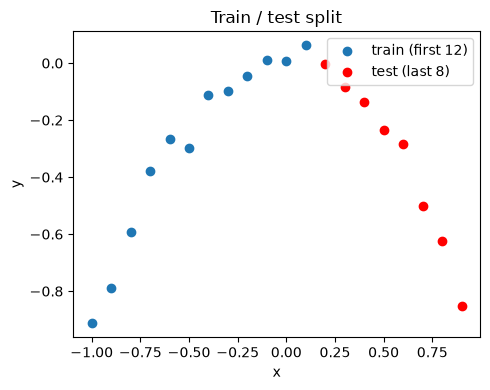

In [5]:
# To-Do: split into train (first 12 points) and test (last 8 points)
x_train, y_train = x[:12], y[:12]    # indices 0..11
x_test,  y_test  = x[12:], y[12:]    # indices 12..19
print("train sizes:", x_train.shape, y_train.shape, "test sizes:", x_test.shape, y_test.shape)
print("train x range:", x_train.min().round(1), "to", x_train.max().round(1),
      "| test x range:", x_test.min().round(1), "to", x_test.max().round(1))

# scatter with the two sets in different colours
plt.figure(figsize=(5,4))
plt.scatter(x_train, y_train, label="train (first 12)")
plt.scatter(x_test, y_test, color="red", label="test (last 8)")
plt.title("Train / test split"); plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.tight_layout(); plt.show()

**What this shows:** 12 training points on the left part of the curve (x ≤ 0.1) and 8 test points on the right part (x ≥ 0.2).

**Learning point**  
Visualizing noisy data helps separate signal from noise. Splitting into train and test allows you to detect when a model overfits noise instead of learning the underlying pattern.

## 🌟 Exercise 4: Fitting Polynomial Models of Different Degrees

**As stated in the exercise**  
Objective: Fit polynomial models of varying degrees and observe overfitting.  

Instructions: Define `polynomial_fit(degree)` that returns the fitted polynomial coefficients from training data. Define `plot_polyfit(degree)` that draws the training set, the test set, and the fitted polynomial curve. Visualize fits for degrees 1, 7, and 11. Observe behavior on training and test sets as degree increases.

**What this cell does:** defines `polynomial_fit(degree)`.
- `np.polyfit(x_train, y_train, degree)` finds the polynomial of that degree with the **smallest squared error on the training points** (least squares). It returns the coefficients, highest power first. Example for degree 2: `[a, b, c]` means a·x² + b·x + c.
- `np.poly1d(coeffs)` wraps the coefficients into a *callable* object, so I can write `p(0.5)` or `p(x_test)` to get predictions.
- Only the **training** data is used for fitting. The test data is kept aside for checking.

In [6]:
# To-Do: implement polynomial_fit
def polynomial_fit(degree: int):
    coeffs = np.polyfit(x_train, y_train, degree)   # least-squares fit on the TRAINING set only
    return np.poly1d(coeffs)                        # callable polynomial: p(x) -> predictions

# quick check: a degree-2 fit should be close to the true rule y = -1·x² + 0·x + 0
p2 = polynomial_fit(2)
print("degree-2 coefficients [x², x, 1]:", np.round(p2.coefficients, 3))

degree-2 coefficients [x², x, 1]: [-0.867  0.075  0.028]


**What this shows:** the degree-2 fit gives about **-0.867·x² + 0.075·x + 0.028**. The true rule is -1·x² + 0·x + 0, so the shape is right but the numbers are a bit off. That is because the fit only sees 12 noisy points, all on the left half of the curve.

**What this cell does:** defines `plot_polyfit(degree)`, which follows the 5 steps of the template:
1. fit the polynomial on the training data,
2. make 200 evenly spaced x values (`np.linspace`) over the whole x range, so the curve is drawn smoothly *between* the data points,
3. evaluate the polynomial at those x values,
4. draw the train points, the test points and the curve,
5. show the plot. I also print the train and test RMSE in the title, so I can compare numbers, not just pictures.

`plt.ylim` fixes the vertical range. High-degree curves can shoot off to huge values, and without a fixed range the data points would be squashed into a flat line.

In [7]:
# To-Do: implement plot_polyfit
def rmse(y_true, y_pred):
    # Root Mean Squared Error = sqrt(average of squared errors), in the same units as y
    return np.sqrt(mean_squared_error(y_true, y_pred))

def plot_polyfit(degree: int):
    # 1) fit
    p = polynomial_fit(degree)
    # 2) create a dense linspace over x range
    x_dense = np.linspace(x.min(), x.max(), 200)
    # 3) evaluate fitted polynomial
    y_dense = p(x_dense)
    # 4) scatter train and test, and plot curve
    tr, te = rmse(y_train, p(x_train)), rmse(y_test, p(x_test))
    plt.figure(figsize=(5,4))
    plt.scatter(x_train, y_train, label="train")
    plt.scatter(x_test, y_test, color="red", label="test")
    plt.plot(x_dense, y_dense, color="green", label=f"degree {degree} fit")
    plt.plot(x_dense, -x_dense**2, "k:", label="true y = -x²")
    plt.ylim(-1.6, 0.6)                     # keep the data visible even if the curve explodes
    plt.title(f"Degree {degree}: train RMSE={tr:.3f}, test RMSE={te:.3f}")
    plt.xlabel("x"); plt.ylabel("y"); plt.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    # 5) display
    plt.show()

**What this cell does:** calls the function for the three degrees the exercise asks for.

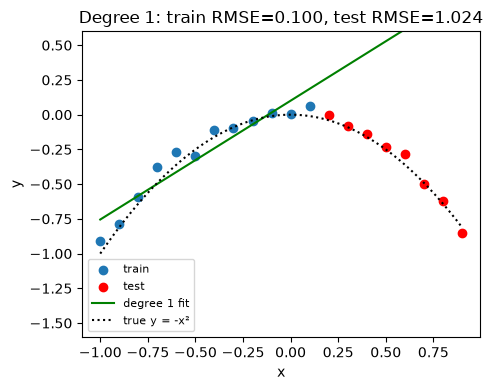

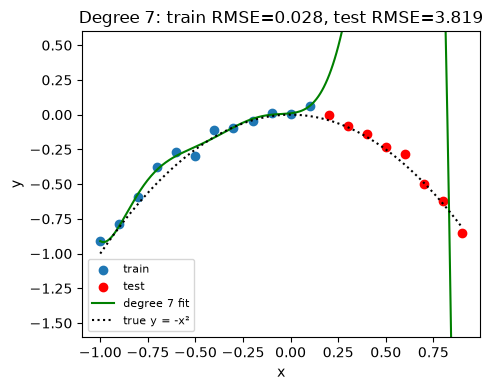

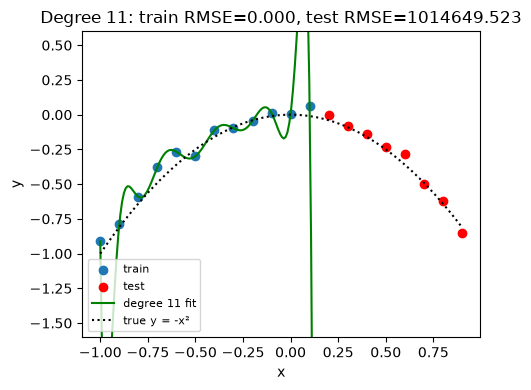

In [8]:
# To-Do: visualize degrees 1, 7, and 11
plot_polyfit(1)
plot_polyfit(7)
plot_polyfit(11)

**What this shows / my observation:** As the degree goes up, the curve follows the training points more and more closely, but it behaves worse and worse on the test points.
- **Degree 1** (a straight line) is too simple. It cannot bend, so it misses both sets: train RMSE 0.100 and test RMSE 1.024. This is **underfitting** (high bias).
- **Degree 7** fits the training points well (train RMSE 0.028), but right after the last training point (x = 0.1) the curve shoots up and then down, far from the red test points (test RMSE 3.819).
- **Degree 11** has 12 coefficients for 12 training points, so it passes exactly through every one of them (train RMSE ≈ 0), wiggles between them, and explodes outside the training range (test RMSE ≈ 1,014,650). This is extreme **overfitting** (high variance): it memorized the noise instead of learning the parabola.

**Learning point**  
Higher degree polynomials can perfectly fit training data yet fail to generalize. This is overfitting. You should always check test error, not just training error.

![image.png](https://github.com/user-attachments/assets/cdfb495c-066a-4efb-a361-f4b9d4ade35c)

## 🌟 Exercise 5: Cross-Validation to Find the Optimal Degree

**As stated in the exercise**  
Objective: Use cross-validation to determine the best polynomial degree.  

Instructions: Loop degrees from 1 to 11. For each degree, compute the RMSE on the training and test sets. Store results in a list. Plot RMSE vs degree with a logarithmic y axis. Identify the degree minimizing test RMSE and confirm it matches the true model \(y=-x^2\).

**What this cell does:** for every degree from 1 to 11 it fits a polynomial on the training set, measures RMSE on the training set and on the test set, and stores `(degree, rmse_train, rmse_test)` as one row in the list `rows`. I then show the rows as a small table with pandas, and find the degree with the smallest test RMSE using `min(..., key=...)`.

In [9]:
# To-Do: compute RMSE per degree for train and test
import pandas as pd

degrees = range(1, 12)
rows = []  # each row: (degree, rmse_train, rmse_test)
for d in degrees:
    p = polynomial_fit(d)                       # fit on train
    r_tr = rmse(y_train, p(x_train))            # error on the points it was fitted on
    r_te = rmse(y_test,  p(x_test))             # error on unseen points
    rows.append((d, r_tr, r_te))                # append to rows

table = pd.DataFrame(rows, columns=["degree", "rmse_train", "rmse_test"])
print(table.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

best_degree, best_tr, best_te = min(rows, key=lambda r: r[2])   # row with the smallest test RMSE
print(f"\nBest degree on the test set: {best_degree} (test RMSE = {best_te:.4f})")
rmse_deg2 = rows[1][2]
print(f"Degree 2 (true model) test RMSE = {rmse_deg2:.4f}")
print(f"Noise level (std of the added noise) = 0.05")

 degree  rmse_train  rmse_test
      1      0.1002      1.024
      2     0.04115     0.1258
      3     0.03734     0.7697
      4     0.03684        1.7
      5     0.03494      6.207
      6     0.02837      58.83
      7     0.02813      3.819
      8     0.02756      523.8
      9     0.02087  1.017e+04
     10      0.0206  2.556e+04
     11   1.517e-10  1.015e+06

Best degree on the test set: 2 (test RMSE = 0.1258)
Degree 2 (true model) test RMSE = 0.1258
Noise level (std of the added noise) = 0.05


**What this cell does (Pre-filled, uncommented):** draws both RMSE curves on one chart. `plt.yscale("log")` uses a logarithmic y axis, because the errors range from tiny (high-degree training error) to very large (high-degree test error), and a normal axis would hide the small values.

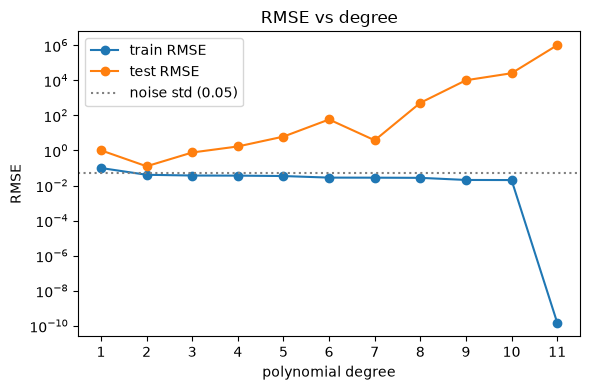

In [10]:
# Pre-filled: plotting RMSE curves (one figure, two curves)
degs = [r[0] for r in rows]
rmse_tr = [r[1] for r in rows]
rmse_te = [r[2] for r in rows]
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(degs, rmse_tr, marker="o", label="train RMSE")
plt.plot(degs, rmse_te, marker="o", label="test RMSE")
plt.axhline(0.05, color="gray", ls=":", label="noise std (0.05)")
plt.yscale("log")
plt.xlabel("polynomial degree")
plt.ylabel("RMSE")
plt.title("RMSE vs degree")
plt.xticks(degs)
plt.legend()
plt.tight_layout()
plt.show()

**What this shows:** the training RMSE (blue) goes down almost every time the degree goes up, and drops to about 1.5e-10 at degree 11, where the polynomial goes exactly through all 12 training points. A more flexible model can always fit the points it was trained on better. The test RMSE (orange) tells a different story: it is lowest at **degree 2 (0.126)** and then grows quickly, to about 1.0e+06 at degree 11. The point where the two curves split apart is where overfitting starts. Even the best test RMSE (0.126) is above the noise level of 0.05, because the test points are outside the training range and any small error in the fitted coefficients grows as x moves away from the training data.

**Extra check: the same experiment with a random split.** The exercise's split tests extrapolation. To check that the method itself points to the true degree when the test points lie *inside* the training range, I repeat the loop with a random 12/8 split of the same 20 points (fixed seed).

In [11]:
# Extra: random 12/8 split (interpolation instead of extrapolation)
rng = np.random.default_rng(0)
idx = rng.permutation(len(x))                  # shuffled indices 0..19
tr_idx, te_idx = idx[:12], idx[12:]
rows_rand = []
for d in degrees:
    p = np.poly1d(np.polyfit(x[tr_idx], y[tr_idx], d))
    rows_rand.append((d, rmse(y[tr_idx], p(x[tr_idx])), rmse(y[te_idx], p(x[te_idx]))))
table_rand = pd.DataFrame(rows_rand, columns=["degree", "rmse_train", "rmse_test"])
print(table_rand.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
best_rand = min(rows_rand, key=lambda r: r[2])
print(f"\nRandom split - best degree on the test set: {best_rand[0]} (test RMSE = {best_rand[2]:.4f})")

 degree  rmse_train  rmse_test
      1      0.3135     0.2749
      2     0.03485    0.05139
      3      0.0336    0.04842
      4     0.02613    0.05535
      5     0.02562    0.05841
      6     0.02517    0.05796
      7     0.01315      0.107
      8     0.01166     0.1835
      9    0.009491     0.5068
     10    0.007511     0.3735
     11   2.009e-13      7.562

Random split - best degree on the test set: 3 (test RMSE = 0.0484)


**What this shows:** with a random split the test points sit between training points. Degree 1 is still clearly too simple (test RMSE 0.275), and degrees 2 to 6 are all close together (0.048 to 0.058, near the noise level of 0.05). The minimum is at **degree 3 (0.0484)**, just below degree 2 (0.0514). The x³ term only fits a little of the noise, and with 8 test points this tiny gap is within chance. From degree 7 onward the test error grows again (up to 7.56 at degree 11). So the U shape and the overfitting are the same with both splits. The extrapolation split simply punishes too much flexibility much more strongly.

**To-Do:** Report the degree with the minimum test RMSE and explain in 2–3 sentences how this connects to the true model \(y=-x^2\) and the bias–variance trade off.

**My answer:** The degree with the minimum test RMSE is **2** (test RMSE = 0.126, train RMSE = 0.041). This **matches the true model y = -x²**, which is a degree-2 polynomial. Degree 1 has too much **bias**: a line cannot bend like a parabola, so both errors are high. Degrees above 2 have too much **variance**: the extra coefficients fit the noise in the 12 training points, so the training error keeps going down while the test error grows, especially because the test points (x = 0.2 to 0.9) are outside the training range (x = -1.0 to 0.1) and a high-degree polynomial swings wildly when it extrapolates. Degree 2 is the balance point of the bias–variance trade-off. One caveat: this split tests extrapolation, not a random sample. With a random 12/8 split (extra check above), degrees 2 and 3 are almost tied (0.051 vs 0.048), so a small test set cannot always separate the true degree from a slightly bigger one.